In [2]:
import pandas as pd
from pathlib import Path
import pyarrow.parquet as pq



from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

RUTA_PROYECTO = Path("..")
RUTA_PROCESSED = RUTA_PROYECTO / "data" / "procesado"

carpeta_etiquetadas = (
    RUTA_PROCESSED / "resenas_etiquetadas"
)

archivos_etiquetados = sorted(
    carpeta_etiquetadas.glob(
        "resenas_etiquetadas_*.parquet"
    )
)

print(
    "Archivos etiquetados encontrados:",
    len(archivos_etiquetados)
)

Archivos etiquetados encontrados: 47


In [7]:
from pathlib import Path

import pandas as pd
import pyarrow.parquet as pq


# ============================================================
# DEFINICIÓN DE RUTAS
# ============================================================

# El notebook se ejecuta desde una carpeta situada un nivel
# por debajo de la raíz del proyecto, por ejemplo notebooks/.
RUTA_PROYECTO = Path("..")

RUTA_raiz = (
    RUTA_PROYECTO
    / "data"
    / "raiz"
)

RUTA_provisional = (
    RUTA_PROYECTO
    / "data"
    / "provisional"
)

RUTA_provisional.mkdir(
    parents=True,
    exist_ok=True,
)

ruta_resenas = (
    RUTA_raiz
    / "Video_Games.jsonl.gz"
)

ruta_metadatos = (
    RUTA_raiz
    / "meta_Video_Games.jsonl.gz"
)

ruta_metadatos_filtrados = (
    RUTA_provisional
    / "metadatos_videojuegos.parquet"
)


# ============================================================
# COMPROBACIÓN DEL ARCHIVO
# ============================================================

if not ruta_metadatos_filtrados.is_file():
    raise FileNotFoundError(
        "No se encontró el archivo de metadatos:\n"
        f"{ruta_metadatos_filtrados.resolve()}"
    )

print("Archivo analizado:")
print(ruta_metadatos_filtrados.resolve())


# ============================================================
# COMPROBACIÓN DEL ESQUEMA PARQUET
# ============================================================

archivo_parquet = pq.ParquetFile(
    ruta_metadatos_filtrados
)

# schema_arrow.names devuelve las columnas principales.
# Es preferible a schema.names cuando existen columnas
# anidadas, como listas.
columnas = archivo_parquet.schema_arrow.names

print("\nColumnas principales del archivo:")

for columna in columnas:
    print(f"  - {columna}")

print(
    "\n¿Contiene la columna 'categories'?",
    "categories" in columnas,
)

if "categories" not in columnas:
    raise ValueError(
        "El archivo no contiene la columna 'categories'."
    )


# ============================================================
# CARGA DE LOS METADATOS
# ============================================================

columnas_necesarias = [
    "parent_asin",
    "main_category",
    "product_title",
    "product_average_rating",
    "product_rating_number",
    "store",
    "categories",
]

metadatos_videojuegos = pd.read_parquet(
    ruta_metadatos_filtrados,
    columns=columnas_necesarias,
)

print("\nNúmero total de videojuegos:")
print(f"{len(metadatos_videojuegos):,}")

print("\nColumnas cargadas en el DataFrame:")
print(
    metadatos_videojuegos.columns.tolist()
)


# ============================================================
# COMPROBACIÓN DE CATEGORIES
# ============================================================

categorias_validas = (
    metadatos_videojuegos["categories"]
    .dropna()
)

print("\nValores no nulos en 'categories':")
print(f"{len(categorias_validas):,}")

print("\nValores nulos en 'categories':")
print(
    f"{metadatos_videojuegos['categories'].isna().sum():,}"
)

if not categorias_validas.empty:
    primer_valor = categorias_validas.iloc[0]

    print("\nTipo del primer valor no nulo:")
    print(type(primer_valor))

    print("\nPrimer valor de 'categories':")
    print(primer_valor)

    if isinstance(
        primer_valor,
        (list, tuple),
    ):
        print("\nElementos de la primera categoría:")

        for elemento in primer_valor:
            print(f"  - {elemento}")


# ============================================================
# MUESTRA ALEATORIA DE VIDEOJUEGOS
# ============================================================

muestra_videojuegos = (
    metadatos_videojuegos[
        [
            "product_title",
            "main_category",
            "categories",
            "parent_asin",
        ]
    ]
    .sample(
        n=min(
            30,
            len(metadatos_videojuegos),
        ),
        random_state=42,
    )
    .reset_index(drop=True)
)

print("\nMuestra aleatoria de 30 videojuegos:")

display(muestra_videojuegos)


# ============================================================
# EJEMPLOS DE VIDEOJUEGOS CON CATEGORÍAS
# ============================================================

videojuegos_con_categorias = (
    metadatos_videojuegos[
        metadatos_videojuegos[
            "categories"
        ].notna()
    ][
        [
            "product_title",
            "main_category",
            "categories",
            "parent_asin",
        ]
    ]
    .head(20)
    .reset_index(drop=True)
)

print(
    "\nPrimeros 20 videojuegos con categorías disponibles:"
)

display(videojuegos_con_categorias)


# ============================================================
# RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN")
print("=" * 70)

print(
    "La columna 'categories' sí existe en el archivo "
    "de metadatos."
)

print(
    "No forma parte de los bloques de reseñas etiquetadas."
)

print(
    "La relación entre ambos conjuntos se realiza mediante:"
)

print(
    "reseña.parent_asin -> "
    "metadatos.parent_asin -> "
    "metadatos.categories"
)

Archivo analizado:
C:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\data\provisional\metadatos_videojuegos.parquet

Columnas principales del archivo:
  - parent_asin
  - main_category
  - product_title
  - product_average_rating
  - product_rating_number
  - store
  - categories

¿Contiene la columna 'categories'? True

Número total de videojuegos:
46,533

Columnas cargadas en el DataFrame:
['parent_asin', 'main_category', 'product_title', 'product_average_rating', 'product_rating_number', 'store', 'categories']

Valores no nulos en 'categories':
46,533

Valores nulos en 'categories':
0

Tipo del primer valor no nulo:
<class 'numpy.ndarray'>

Primer valor de 'categories':
['Video Games' 'PC' 'Games']

Muestra aleatoria de 30 videojuegos:


,product_title,main_category,categories,parent_asin
0,Transformers: Dark of the Moon Decepticons - N...,Video Games,"[Video Games, Legacy Systems, Nintendo Systems...",B004MXTZTS
1,Nba 2K18 Legend Gold Edition - Xbox One,Video Games,"[Video Games, Xbox One, Games]",B0741B5N1F
2,Grand Theft Auto: Episodes from Liberty City [...,Video Games,"[Video Games, PC, Games]",B004D4YDPC
3,Fullmetal Alchemist Trading Card Game - Ninten...,Video Games,"[Video Games, Legacy Systems, Nintendo Systems...",B000P97E8M
4,Steep Gold Edition - PS4 [Digital Code],Video Games,"[Video Games, PlayStation Digital Content, Games]",B01N1NBERC
5,Return to Krondor,Video Games,"[Video Games, PC, Games]",B000W2K876
6,For Honor: Battle Pass - Year 4 Season 1 - PS4...,Video Games,"[Video Games, PlayStation Digital Content, Games]",B08527ZXQ1
7,Reel Deal Card Games 2011 [Download],Video Games,"[Video Games, PC, Games]",B00571X5OU
8,Cities Skylines (PS4),Video Games,"[Video Games, PlayStation 4, Games]",B07D6X9QLW
9,Call Of Duty: Ghosts /xbox One,Video Games,"[Video Games, Xbox One, Games]",B00CM1KWAS



Primeros 20 videojuegos con categorías disponibles:


,product_title,main_category,categories,parent_asin
0,Dash 8-300 Professional Add-On,Video Games,"[Video Games, PC, Games]",B000FH0MHO
1,Phantasmagoria: A Puzzle of Flesh,Video Games,"[Video Games, PC, Games]",B00069EVOG
2,NBA 2K17 - Early Tip Off Edition - PlayStation 4,Video Games,"[Video Games, PlayStation 4, Games]",B00Z9TLVK0
3,Nintendo Selects: The Legend of Zelda Ocarina ...,Video Games,"[Video Games, Legacy Systems, Nintendo Systems...",B07SZJZV88
4,Grand Prix 4,Video Games,"[Video Games, PC, Games]",B00005Y3OJ
5,"Spongebob Squarepants, Vol. 1",Video Games,"[Video Games, Legacy Systems, Nintendo Systems...",B0001ZNU56
6,Konami Collector's Series: Castlevania & Contr...,Video Games,"[Video Games, PC, Games]",B00006969T
7,Tales of Vesperia - Definitive Edition - PlayS...,Video Games,"[Video Games, PlayStation 4, Games]",B07DL353F8
8,"Warhammer 40,000 Dawn of War Game of the Year ...",Video Games,"[Video Games, PC, Games]",B001EYUX4Y
9,Tiger Heli - Nintendo NES,Video Games,"[Video Games, Legacy Systems, Nintendo Systems...",B00004SVXD



RESUMEN
La columna 'categories' sí existe en el archivo de metadatos.
No forma parte de los bloques de reseñas etiquetadas.
La relación entre ambos conjuntos se realiza mediante:
reseña.parent_asin -> metadatos.parent_asin -> metadatos.categories


In [8]:
import pandas as pd


# ============================================================
# NORMALIZACIÓN DE LA COLUMNA CATEGORIES
# ============================================================

def convertir_a_lista(valor):
    """
    Convierte el contenido de categories en una lista limpia.
    """
    if valor is None:
        return []

    if hasattr(valor, "tolist"):
        valor = valor.tolist()

    if isinstance(valor, tuple):
        valor = list(valor)

    if isinstance(valor, list):
        return [
            str(elemento).strip()
            for elemento in valor
            if elemento is not None
            and str(elemento).strip()
        ]

    try:
        if pd.isna(valor):
            return []
    except (TypeError, ValueError):
        pass

    texto = str(valor).strip()

    return [texto] if texto else []


metadatos_videojuegos = (
    metadatos_videojuegos.copy()
)

metadatos_videojuegos[
    "categories_lista"
] = metadatos_videojuegos[
    "categories"
].apply(convertir_a_lista)


# ============================================================
# EXPLOSIÓN DE LAS CATEGORÍAS
# ============================================================

categorias_separadas = (
    metadatos_videojuegos[
        [
            "parent_asin",
            "product_title",
            "main_category",
            "categories_lista",
        ]
    ]
    .explode("categories_lista")
    .rename(
        columns={
            "categories_lista": "categoria",
        }
    )
)

categorias_separadas["categoria"] = (
    categorias_separadas["categoria"]
    .fillna("")
    .astype(str)
    .str.strip()
)

categorias_separadas = (
    categorias_separadas[
        categorias_separadas["categoria"] != ""
    ]
    .reset_index(drop=True)
)


# ============================================================
# FRECUENCIAS
# ============================================================

frecuencia_categorias = (
    categorias_separadas["categoria"]
    .value_counts()
    .rename_axis("categoria")
    .reset_index(name="numero_videojuegos")
)

print(
    "Número de videojuegos:",
    f"{len(metadatos_videojuegos):,}",
)

print(
    "Número de asignaciones de categorías:",
    f"{len(categorias_separadas):,}",
)

print(
    "Número de categorías diferentes:",
    f"{categorias_separadas['categoria'].nunique():,}",
)

display(
    frecuencia_categorias.head(100)
)


Número de videojuegos: 46,533
Número de asignaciones de categorías: 182,422
Número de categorías diferentes: 56


,categoria,numero_videojuegos
0,Video Games,46533
1,Games,46533
2,Legacy Systems,20583
3,PC,17758
4,Nintendo Systems,8869
5,PlayStation Systems,7056
6,Xbox Systems,2754
7,PlayStation 4,2689
8,PlayStation 2,2254
9,Nintendo Switch,2229


In [10]:

# ============================================================
# PLATAFORMAS CONCRETAS
# ============================================================

# El orden es importante.
# Las plataformas concretas aparecen antes que las familias
# generales para que tengan prioridad.

PLATAFORMAS_ESPECIFICAS = [
    # PlayStation
    "PlayStation 5",
    "PlayStation 4",
    "PlayStation 3",
    "PlayStation 2",
    "PlayStation Vita",
    "Sony PSP",
    "PlayStation",
    "PlayStation Digital Content",

    # Xbox
    "Xbox Series X & S",
    "Xbox One",
    "Xbox 360",
    "Xbox",
    "Xbox Digital Content",

    # Nintendo
    "Nintendo Switch",
    "Nintendo 3DS & 2DS",
    "Nintendo DS",
    "Wii U",
    "Wii",
    "GameCube",
    "Nintendo 64",
    "Super Nintendo",
    "Nintendo NES",
    "Game Boy Advance",
    "Game Boy Color",
    "Game Boy",

    # Sega
    "Sega Dreamcast",
    "Sega Saturn",
    "Sega Genesis",
    "Sega Game Gear",
    "Sega Master System",
    "Sega CD",

    # Atari
    "Atari 2600",
    "Atari 5200",
    "Atari 7800",
    "Atari Jaguar",
    "Atari Lynx",

    # Commodore
    "Commodore Amiga",
    "Commodore 64",

    # Otros sistemas
    "TurboGrafx 16",
    "ColecoVision",
    "Intellivision",
    "3DO",
    "NEOGEO Pocket",

    # Ordenadores
    "PC",
    "Mac",
]


# ============================================================
# FAMILIAS GENERALES
# ============================================================

FAMILIA_POR_PLATAFORMA = {
    # PlayStation
    "PlayStation 5": "PlayStation",
    "PlayStation 4": "PlayStation",
    "PlayStation 3": "PlayStation",
    "PlayStation 2": "PlayStation",
    "PlayStation Vita": "PlayStation",
    "Sony PSP": "PlayStation",
    "PlayStation": "PlayStation",
    "PlayStation Digital Content": "PlayStation",

    # Xbox
    "Xbox Series X & S": "Xbox",
    "Xbox One": "Xbox",
    "Xbox 360": "Xbox",
    "Xbox": "Xbox",
    "Xbox Digital Content": "Xbox",

    # Nintendo
    "Nintendo Switch": "Nintendo",
    "Nintendo 3DS & 2DS": "Nintendo",
    "Nintendo DS": "Nintendo",
    "Wii U": "Nintendo",
    "Wii": "Nintendo",
    "GameCube": "Nintendo",
    "Nintendo 64": "Nintendo",
    "Super Nintendo": "Nintendo",
    "Nintendo NES": "Nintendo",
    "Game Boy Advance": "Nintendo",
    "Game Boy Color": "Nintendo",
    "Game Boy": "Nintendo",

    # Sega
    "Sega Dreamcast": "Sega",
    "Sega Saturn": "Sega",
    "Sega Genesis": "Sega",
    "Sega Game Gear": "Sega",
    "Sega Master System": "Sega",
    "Sega CD": "Sega",

    # Atari
    "Atari 2600": "Atari",
    "Atari 5200": "Atari",
    "Atari 7800": "Atari",
    "Atari Jaguar": "Atari",
    "Atari Lynx": "Atari",

    # Commodore
    "Commodore Amiga": "Commodore",
    "Commodore 64": "Commodore",

    # Otros sistemas
    "TurboGrafx 16": "Otros sistemas",
    "ColecoVision": "Otros sistemas",
    "Intellivision": "Otros sistemas",
    "3DO": "Otros sistemas",
    "NEOGEO Pocket": "Otros sistemas",

    # Ordenadores
    "PC": "PC",
    "Mac": "PC",
}


CATEGORIAS_GENERALES_POR_FAMILIA = {
    "PlayStation Systems": "PlayStation",
    "Xbox Systems": "Xbox",
    "Nintendo Systems": "Nintendo",
    "Game Boy Systems": "Nintendo",
    "Sega Systems": "Sega",
    "Atari Systems": "Atari",
    "Commodore Systems": "Commodore",
    "Handheld Game Systems": "Otros sistemas",
    "Legacy Systems": "Otros sistemas",
}


# ============================================================
# OBTENCIÓN DE PLATAFORMAS
# ============================================================

def obtener_plataformas(categorias):
    """
    Devuelve todas las plataformas concretas encontradas.
    """
    categorias = convertir_a_lista(
        categorias
    )

    conjunto_categorias = set(categorias)

    return [
        plataforma
        for plataforma in PLATAFORMAS_ESPECIFICAS
        if plataforma in conjunto_categorias
    ]


def obtener_plataforma_principal(categorias):
    """
    Devuelve la plataforma más específica encontrada.

    Si no existe una plataforma concreta, utiliza una
    categoría general como Nintendo Systems o Legacy Systems.
    """
    categorias = convertir_a_lista(
        categorias
    )

    conjunto_categorias = set(categorias)

    # Primero se buscan plataformas concretas.
    for plataforma in PLATAFORMAS_ESPECIFICAS:
        if plataforma in conjunto_categorias:
            return plataforma

    # Si no hay una plataforma concreta, se utiliza
    # la familia general disponible.
    for categoria_general in (
        CATEGORIAS_GENERALES_POR_FAMILIA
    ):
        if categoria_general in conjunto_categorias:
            return categoria_general

    return None


def obtener_familia_plataforma(
    categorias,
    plataforma_principal,
):
    """
    Obtiene la familia de la plataforma.
    """
    if plataforma_principal in FAMILIA_POR_PLATAFORMA:
        return FAMILIA_POR_PLATAFORMA[
            plataforma_principal
        ]

    if (
        plataforma_principal
        in CATEGORIAS_GENERALES_POR_FAMILIA
    ):
        return CATEGORIAS_GENERALES_POR_FAMILIA[
            plataforma_principal
        ]

    categorias = convertir_a_lista(
        categorias
    )

    conjunto_categorias = set(categorias)

    # Segunda comprobación mediante categorías generales.
    for categoria_general, familia in (
        CATEGORIAS_GENERALES_POR_FAMILIA.items()
    ):
        if categoria_general in conjunto_categorias:
            return familia

    return None


# ============================================================
# APLICACIÓN AL DATAFRAME
# ============================================================

metadatos_videojuegos["plataformas"] = (
    metadatos_videojuegos["categories_lista"]
    .apply(obtener_plataformas)
)

metadatos_videojuegos["plataforma_principal"] = (
    metadatos_videojuegos["categories_lista"]
    .apply(obtener_plataforma_principal)
)

metadatos_videojuegos["familia_plataforma"] = (
    metadatos_videojuegos.apply(
        lambda fila: obtener_familia_plataforma(
            categorias=fila["categories_lista"],
            plataforma_principal=(
                fila["plataforma_principal"]
            ),
        ),
        axis=1,
    )
)


# ============================================================
# CATEGORÍAS QUE NO SON PLATAFORMAS
# ============================================================

CATEGORIAS_DE_PLATAFORMA = (
    set(PLATAFORMAS_ESPECIFICAS)
    | set(CATEGORIAS_GENERALES_POR_FAMILIA)
)


def obtener_categorias_no_plataforma(categorias):
    """
    Conserva las categorías que no identifican una plataforma
    ni una familia de sistemas.
    """
    categorias = convertir_a_lista(
        categorias
    )

    return [
        categoria
        for categoria in categorias
        if categoria not in CATEGORIAS_DE_PLATAFORMA
        and categoria not in {
            "Video Games",
            "Games",
        }
    ]


metadatos_videojuegos["categorias_adicionales"] = (
    metadatos_videojuegos["categories_lista"]
    .apply(obtener_categorias_no_plataforma)
)


# ============================================================
# COMPROBACIÓN DE RESULTADOS
# ============================================================

columnas_resultado = [
    "product_title",
    "categories",
    "plataformas",
    "plataforma_principal",
    "familia_plataforma",
    "categorias_adicionales",
    "parent_asin",
]

print("Muestra de videojuegos clasificados:")

display(
    metadatos_videojuegos[
        columnas_resultado
    ]
    .sample(
        n=min(
            50,
            len(metadatos_videojuegos),
        ),
        random_state=42,
    )
    .reset_index(drop=True)
)

Muestra de videojuegos clasificados:


,product_title,categories,plataformas,plataforma_principal,familia_plataforma,categorias_adicionales,parent_asin
0,Transformers: Dark of the Moon Decepticons - N...,"[Video Games, Legacy Systems, Nintendo Systems...",[Nintendo DS],Nintendo DS,Nintendo,[],B004MXTZTS
1,Nba 2K18 Legend Gold Edition - Xbox One,"[Video Games, Xbox One, Games]",[Xbox One],Xbox One,Xbox,[],B0741B5N1F
2,Grand Theft Auto: Episodes from Liberty City [...,"[Video Games, PC, Games]",[PC],PC,PC,[],B004D4YDPC
3,Fullmetal Alchemist Trading Card Game - Ninten...,"[Video Games, Legacy Systems, Nintendo Systems...",[Nintendo DS],Nintendo DS,Nintendo,[],B000P97E8M
4,Steep Gold Edition - PS4 [Digital Code],"[Video Games, PlayStation Digital Content, Games]",[PlayStation Digital Content],PlayStation Digital Content,PlayStation,[],B01N1NBERC
5,Return to Krondor,"[Video Games, PC, Games]",[PC],PC,PC,[],B000W2K876
6,For Honor: Battle Pass - Year 4 Season 1 - PS4...,"[Video Games, PlayStation Digital Content, Games]",[PlayStation Digital Content],PlayStation Digital Content,PlayStation,[],B08527ZXQ1
7,Reel Deal Card Games 2011 [Download],"[Video Games, PC, Games]",[PC],PC,PC,[],B00571X5OU
8,Cities Skylines (PS4),"[Video Games, PlayStation 4, Games]",[PlayStation 4],PlayStation 4,PlayStation,[],B07D6X9QLW
9,Call Of Duty: Ghosts /xbox One,"[Video Games, Xbox One, Games]",[Xbox One],Xbox One,Xbox,[],B00CM1KWAS


In [11]:
distribucion_familias = (
    metadatos_videojuegos[
        "familia_plataforma"
    ]
    .fillna("Sin plataforma identificada")
    .value_counts()
    .rename_axis("familia_plataforma")
    .reset_index(name="numero_videojuegos")
)

distribucion_familias["porcentaje"] = (
    distribucion_familias[
        "numero_videojuegos"
    ]
    .div(
        len(metadatos_videojuegos)
    )
    .mul(100)
    .round(2)
)

display(distribucion_familias)

,familia_plataforma,numero_videojuegos,porcentaje
0,PC,18523,39.81
1,Nintendo,11098,23.85
2,PlayStation,10758,23.12
3,Xbox,4250,9.13
4,Sega,1425,3.06
5,Atari,265,0.57
6,Otros sistemas,145,0.31
7,Commodore,69,0.15


In [12]:
distribucion_plataformas = (
    metadatos_videojuegos[
        "plataforma_principal"
    ]
    .fillna("Sin plataforma identificada")
    .value_counts()
    .rename_axis("plataforma")
    .reset_index(name="numero_videojuegos")
)

distribucion_plataformas["porcentaje"] = (
    distribucion_plataformas[
        "numero_videojuegos"
    ]
    .div(
        len(metadatos_videojuegos)
    )
    .mul(100)
    .round(2)
)

display(distribucion_plataformas)

,plataforma,numero_videojuegos,porcentaje
0,PC,17758,38.16
1,PlayStation 4,2689,5.78
2,PlayStation 2,2254,4.84
3,Nintendo Switch,2229,4.79
4,PlayStation 3,2137,4.59
5,Nintendo DS,1892,4.07
6,Xbox 360,1873,4.03
7,Wii,1623,3.49
8,Xbox One,1373,2.95
9,PlayStation,1297,2.79


In [13]:
from pathlib import Path

import pandas as pd


RUTA_ETIQUETADAS = (
    RUTA_PROYECTO
    / "data"
    / "procesado"
    / "resenas_etiquetadas"
)

archivos_etiquetados = sorted(
    RUTA_ETIQUETADAS.glob(
        "resenas_etiquetadas_*.parquet"
    )
)

if not archivos_etiquetados:
    raise FileNotFoundError(
        "No se encontraron bloques etiquetados en:\n"
        f"{RUTA_ETIQUETADAS.resolve()}"
    )


resumenes_por_bloque = []

for numero, archivo in enumerate(
    archivos_etiquetados,
    start=1,
):
    bloque = pd.read_parquet(
        archivo,
        columns=[
            "parent_asin",
            "rating",
        ],
    )

    bloque["parent_asin"] = (
        bloque["parent_asin"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    bloque["rating"] = pd.to_numeric(
        bloque["rating"],
        errors="coerce",
    )

    bloque = bloque[
        bloque["parent_asin"].ne("")
        & bloque["rating"].between(
            1,
            5,
            inclusive="both",
        )
    ]

    resumen_bloque = (
        bloque
        .groupby(
            "parent_asin",
            as_index=False,
        )
        .agg(
            suma_puntuaciones=(
                "rating",
                "sum",
            ),
            numero_resenas=(
                "rating",
                "size",
            ),
        )
    )

    resumenes_por_bloque.append(
        resumen_bloque
    )

    print(
        f"[{numero}/{len(archivos_etiquetados)}] "
        f"{archivo.name}: "
        f"{len(bloque):,} reseñas válidas"
    )


resumen_resenas = pd.concat(
    resumenes_por_bloque,
    ignore_index=True,
)

# Un videojuego puede aparecer en varios bloques.
resumen_resenas = (
    resumen_resenas
    .groupby(
        "parent_asin",
        as_index=False,
    )
    .agg(
        suma_puntuaciones=(
            "suma_puntuaciones",
            "sum",
        ),
        numero_resenas=(
            "numero_resenas",
            "sum",
        ),
    )
)

resumen_resenas[
    "puntuacion_media_resenas"
] = (
    resumen_resenas[
        "suma_puntuaciones"
    ]
    / resumen_resenas[
        "numero_resenas"
    ]
)

print()
print(
    "Videojuegos con reseñas válidas:",
    f"{len(resumen_resenas):,}",
)

display(
    resumen_resenas.head()
)

[1/47] resenas_etiquetadas_0000.parquet: 39,175 reseñas válidas
[2/47] resenas_etiquetadas_0001.parquet: 32,192 reseñas válidas
[3/47] resenas_etiquetadas_0002.parquet: 33,664 reseñas válidas
[4/47] resenas_etiquetadas_0003.parquet: 35,123 reseñas válidas
[5/47] resenas_etiquetadas_0004.parquet: 32,876 reseñas válidas
[6/47] resenas_etiquetadas_0005.parquet: 33,926 reseñas válidas
[7/47] resenas_etiquetadas_0006.parquet: 35,786 reseñas válidas
[8/47] resenas_etiquetadas_0007.parquet: 40,786 reseñas válidas
[9/47] resenas_etiquetadas_0008.parquet: 32,918 reseñas válidas
[10/47] resenas_etiquetadas_0009.parquet: 34,528 reseñas válidas
[11/47] resenas_etiquetadas_0010.parquet: 37,276 reseñas válidas
[12/47] resenas_etiquetadas_0011.parquet: 33,484 reseñas válidas
[13/47] resenas_etiquetadas_0012.parquet: 36,178 reseñas válidas
[14/47] resenas_etiquetadas_0013.parquet: 33,400 reseñas válidas
[15/47] resenas_etiquetadas_0014.parquet: 28,976 reseñas válidas
[16/47] resenas_etiquetadas_0015.p

,parent_asin,suma_puntuaciones,numero_resenas,puntuacion_media_resenas
0,0008288194,3,1,3.000000
1,0060501960,76,17,4.470588
2,0072826843,63,14,4.500000
3,0078764343,15,3,5.000000
4,0099428121,25,5,5.000000


In [15]:

metadatos_analisis = (
    metadatos_videojuegos[
        [
            "parent_asin",
            "product_title",
            "categories",
        ]
    ]
    .copy()
)

metadatos_analisis[
    "plataforma"
] = metadatos_analisis[
    "categories"
].apply(obtener_plataforma_principal)

datos_plataformas = (
    metadatos_analisis
    .merge(
        resumen_resenas,
        on="parent_asin",
        how="inner",
        validate="one_to_one",
    )
)

datos_plataformas = (
    datos_plataformas[
        datos_plataformas[
            "plataforma"
        ].notna()
    ]
    .copy()
)


print(
    "Videojuegos incluidos en el análisis:",
    f"{len(datos_plataformas):,}",
)

print(
    "Plataformas diferentes:",
    datos_plataformas[
        "plataforma"
    ].nunique(),
)

display(
    datos_plataformas[
        [
            "product_title",
            "plataforma",
            "numero_resenas",
            "puntuacion_media_resenas",
        ]
    ]
    .head(20)
)

Videojuegos incluidos en el análisis: 46,527
Plataformas diferentes: 45


,product_title,plataforma,numero_resenas,puntuacion_media_resenas
0,Dash 8-300 Professional Add-On,PC,1,5.000000
1,Phantasmagoria: A Puzzle of Flesh,PC,9,4.333333
2,NBA 2K17 - Early Tip Off Edition - PlayStation 4,PlayStation 4,648,4.180556
3,Nintendo Selects: The Legend of Zelda Ocarina ...,Nintendo 3DS & 2DS,3,5.000000
4,Grand Prix 4,PC,1,1.000000
5,"Spongebob Squarepants, Vol. 1",Game Boy Advance,11,4.454545
6,Konami Collector's Series: Castlevania & Contr...,PC,11,3.909091
7,Tales of Vesperia - Definitive Edition - PlayS...,PlayStation 4,23,4.739130
8,"Warhammer 40,000 Dawn of War Game of the Year ...",PC,137,4.218978
9,Tiger Heli - Nintendo NES,Nintendo NES,13,4.307692


In [16]:
MINIMO_VIDEOJUEGOS = 30


resumen_plataformas = (
    datos_plataformas
    .groupby(
        "plataforma",
        as_index=False,
    )
    .agg(
        numero_videojuegos=(
            "parent_asin",
            "nunique",
        ),
        numero_resenas=(
            "numero_resenas",
            "sum",
        ),
        puntuacion_media=(
            "puntuacion_media_resenas",
            "mean",
        ),
        mediana=(
            "puntuacion_media_resenas",
            "median",
        ),
        desviacion_tipica=(
            "puntuacion_media_resenas",
            "std",
        ),
    )
)

resumen_plataformas = (
    resumen_plataformas[
        resumen_plataformas[
            "numero_videojuegos"
        ] >= MINIMO_VIDEOJUEGOS
    ]
    .sort_values(
        "puntuacion_media",
        ascending=False,
    )
    .reset_index(drop=True)
)

resumen_plataformas[
    "puntuacion_media"
] = resumen_plataformas[
    "puntuacion_media"
].round(3)

resumen_plataformas[
    "mediana"
] = resumen_plataformas[
    "mediana"
].round(3)

resumen_plataformas[
    "desviacion_tipica"
] = resumen_plataformas[
    "desviacion_tipica"
].round(3)


display(resumen_plataformas)

,plataforma,numero_videojuegos,numero_resenas,puntuacion_media,mediana,desviacion_tipica
0,TurboGrafx 16,34,81,4.758,5.000,0.476
1,Sega Saturn,294,1607,4.548,5.000,0.704
2,Sega Master System,76,214,4.486,5.000,0.768
3,ColecoVision,31,66,4.473,5.000,0.936
4,PlayStation Vita,529,15405,4.407,4.692,0.871
5,Commodore 64,65,1405,4.404,5.000,1.075
6,Sony PSP,839,15185,4.356,4.500,0.785
7,Intellivision,30,45,4.306,5.000,1.240
8,Super Nintendo,646,6132,4.253,4.500,0.890
9,Atari 2600,171,1600,4.250,4.750,1.023


In [17]:
MINIMO_VIDEOJUEGOS = 30


resumen_plataformas = (
    datos_plataformas
    .groupby(
        "plataforma",
        as_index=False,
    )
    .agg(
        numero_videojuegos=(
            "parent_asin",
            "nunique",
        ),
        numero_resenas=(
            "numero_resenas",
            "sum",
        ),
        puntuacion_media=(
            "puntuacion_media_resenas",
            "mean",
        ),
        mediana=(
            "puntuacion_media_resenas",
            "median",
        ),
        desviacion_tipica=(
            "puntuacion_media_resenas",
            "std",
        ),
    )
)

resumen_plataformas = (
    resumen_plataformas[
        resumen_plataformas[
            "numero_videojuegos"
        ] >= MINIMO_VIDEOJUEGOS
    ]
    .sort_values(
        "puntuacion_media",
        ascending=False,
    )
    .reset_index(drop=True)
)

resumen_plataformas[
    "puntuacion_media"
] = resumen_plataformas[
    "puntuacion_media"
].round(3)

resumen_plataformas[
    "mediana"
] = resumen_plataformas[
    "mediana"
].round(3)

resumen_plataformas[
    "desviacion_tipica"
] = resumen_plataformas[
    "desviacion_tipica"
].round(3)


display(resumen_plataformas)

,plataforma,numero_videojuegos,numero_resenas,puntuacion_media,mediana,desviacion_tipica
0,TurboGrafx 16,34,81,4.758,5.000,0.476
1,Sega Saturn,294,1607,4.548,5.000,0.704
2,Sega Master System,76,214,4.486,5.000,0.768
3,ColecoVision,31,66,4.473,5.000,0.936
4,PlayStation Vita,529,15405,4.407,4.692,0.871
5,Commodore 64,65,1405,4.404,5.000,1.075
6,Sony PSP,839,15185,4.356,4.500,0.785
7,Intellivision,30,45,4.306,5.000,1.240
8,Super Nintendo,646,6132,4.253,4.500,0.890
9,Atari 2600,171,1600,4.250,4.750,1.023


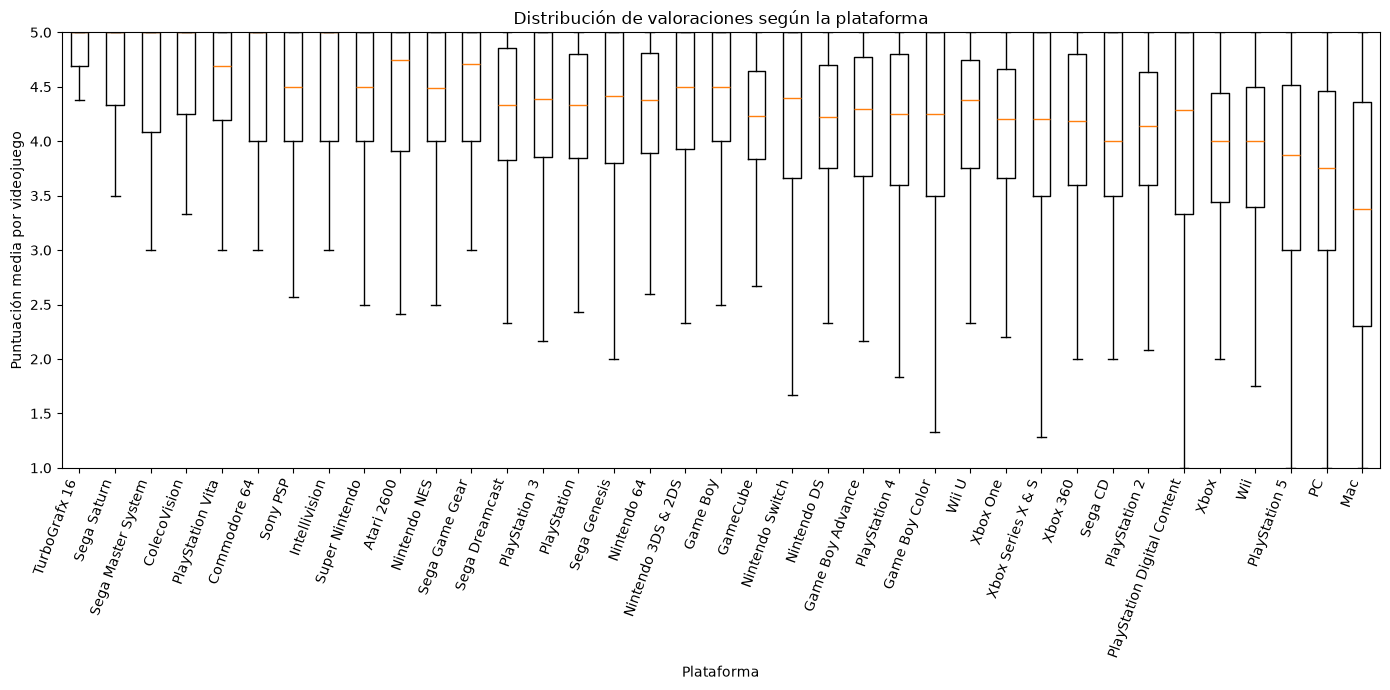

In [19]:

import matplotlib.pyplot as plt

plataformas_validas = set(
    resumen_plataformas[
        "plataforma"
    ]
)

datos_validos = (
    datos_plataformas[
        datos_plataformas[
            "plataforma"
        ].isin(plataformas_validas)
    ]
    .copy()
)

orden_plataformas = (
    resumen_plataformas[
        "plataforma"
    ]
    .tolist()
)

datos_boxplot = [
    datos_validos.loc[
        datos_validos[
            "plataforma"
        ].eq(plataforma),
        "puntuacion_media_resenas",
    ].to_numpy()
    for plataforma in orden_plataformas
]


plt.figure(
    figsize=(14, 7)
)

plt.boxplot(
    datos_boxplot,
    tick_labels=orden_plataformas,
    showfliers=False,
)

plt.xlabel("Plataforma")
plt.ylabel("Puntuación media por videojuego")
plt.title("Distribución de valoraciones según la plataforma")
plt.xticks(
    rotation=70,
    ha="right",
)
plt.ylim(1, 5)
plt.tight_layout()
plt.show()

In [20]:
from scipy.stats import kruskal


grupos = [
    datos_validos.loc[
        datos_validos[
            "plataforma"
        ].eq(plataforma),
        "puntuacion_media_resenas",
    ].dropna().to_numpy()
    for plataforma in orden_plataformas
]

estadistico_h, valor_p = kruskal(
    *grupos
)

print(
    "Estadístico H:",
    round(
        float(estadistico_h),
        4,
    ),
)

print(
    "Valor p:",
    f"{valor_p:.10g}",
)

if valor_p < 0.05:
    print(
        "\nSe rechaza la hipótesis nula."
    )
    print(
        "Existen diferencias estadísticamente "
        "significativas entre las valoraciones "
        "de al menos dos plataformas."
    )
else:
    print(
        "\nNo se rechaza la hipótesis nula."
    )
    print(
        "No se han encontrado diferencias "
        "estadísticamente significativas entre "
        "las plataformas."
    )

Estadístico H: 3527.3646
Valor p: 0

Se rechaza la hipótesis nula.
Existen diferencias estadísticamente significativas entre las valoraciones de al menos dos plataformas.


In [21]:
numero_observaciones = sum(
    len(grupo)
    for grupo in grupos
)

numero_grupos = len(grupos)

epsilon_cuadrado = (
    estadistico_h
    - numero_grupos
    + 1
) / (
    numero_observaciones
    - numero_grupos
)

epsilon_cuadrado = max(
    0.0,
    float(epsilon_cuadrado),
)

print(
    "Número de videojuegos analizados:",
    f"{numero_observaciones:,}",
)

print(
    "Número de plataformas:",
    numero_grupos,
)

print(
    "Epsilon cuadrado:",
    round(epsilon_cuadrado, 4),
)

if epsilon_cuadrado < 0.01:
    interpretacion = "prácticamente nulo"
elif epsilon_cuadrado < 0.06:
    interpretacion = "pequeño"
elif epsilon_cuadrado < 0.14:
    interpretacion = "moderado"
else:
    interpretacion = "grande"

print(
    "Tamaño del efecto:",
    interpretacion,
)

Número de videojuegos analizados: 46,374
Número de plataformas: 37
Epsilon cuadrado: 0.0753
Tamaño del efecto: moderado


In [26]:
from itertools import combinations

import pandas as pd
from scipy.stats import mannwhitneyu


comparaciones = []

for plataforma_a, plataforma_b in combinations(
    orden_plataformas,
    2,
):
    grupo_a = datos_validos.loc[
        datos_validos["plataforma"].eq(
            plataforma_a
        ),
        "puntuacion_media_resenas",
    ].dropna()

    grupo_b = datos_validos.loc[
        datos_validos["plataforma"].eq(
            plataforma_b
        ),
        "puntuacion_media_resenas",
    ].dropna()

    estadistico_u, valor_p = mannwhitneyu(
        grupo_a,
        grupo_b,
        alternative="two-sided",
    )

    comparaciones.append(
        {
            "plataforma_a": plataforma_a,
            "plataforma_b": plataforma_b,
            "media_a": grupo_a.mean(),
            "media_b": grupo_b.mean(),
            "mediana_a": grupo_a.median(),
            "mediana_b": grupo_b.median(),
            "diferencia_medias": (
                grupo_a.mean()
                - grupo_b.mean()
            ),
            "valor_p": valor_p,
        }
    )


comparaciones = pd.DataFrame(
    comparaciones
)


# Corrección de Holm
comparaciones = comparaciones.sort_values(
    "valor_p"
).reset_index(drop=True)

numero_comparaciones = len(comparaciones)

comparaciones["rango"] = (
    comparaciones.index + 1
)

comparaciones["valor_p_holm"] = [
    min(
        valor_p
        * (
            numero_comparaciones
            - indice
        ),
        1.0,
    )
    for indice, valor_p in enumerate(
        comparaciones["valor_p"]
    )
]

comparaciones[
    "significativa"
] = comparaciones[
    "valor_p_holm"
].lt(0.05)


columnas_redondear = [
    "media_a",
    "media_b",
    "mediana_a",
    "mediana_b",
    "diferencia_medias",
]

comparaciones[
    columnas_redondear
] = comparaciones[
    columnas_redondear
].round(3)


comparaciones_significativas = (
    comparaciones[
        comparaciones["significativa"]
    ]
    .sort_values(
        "diferencia_medias",
        key=lambda serie: serie.abs(),
        ascending=False,
    )
    .reset_index(drop=True)
)

print(
    "Comparaciones realizadas:",
    len(comparaciones),
)

print(
    "Comparaciones significativas:",
    len(comparaciones_significativas),
)

display(
    comparaciones_significativas.head(30)
)

Comparaciones realizadas: 666
Comparaciones significativas: 326


,plataforma_a,plataforma_b,media_a,media_b,mediana_a,mediana_b,diferencia_medias,valor_p,rango,valor_p_holm,significativa
0,TurboGrafx 16,Mac,4.758,3.253,5.000,3.375,1.505,1.204068e-11,146,6.273196e-09,True
1,Sega Saturn,Mac,4.548,3.253,5.000,3.375,1.295,2.240676e-49,22,1.445236e-46,True
2,TurboGrafx 16,PC,4.758,3.521,5.000,3.750,1.237,7.059372e-12,141,3.713230e-09,True
3,Sega Master System,Mac,4.486,3.253,5.000,3.375,1.233,2.044058e-15,110,1.138540e-12,True
4,ColecoVision,Mac,4.473,3.253,5.000,3.375,1.220,1.366431e-07,215,6.176268e-05,True
5,PlayStation Vita,Mac,4.407,3.253,4.692,3.375,1.154,5.718859e-57,16,3.722977e-54,True
6,Commodore 64,Mac,4.404,3.253,5.000,3.375,1.151,7.819006e-13,128,4.214444e-10,True
7,TurboGrafx 16,PlayStation 5,4.758,3.636,5.000,3.875,1.122,3.985581e-10,168,1.988805e-07,True
8,Sony PSP,Mac,4.356,3.253,4.500,3.375,1.103,7.240627e-65,11,4.749852e-62,True
9,Intellivision,Mac,4.306,3.253,5.000,3.375,1.052,3.151694e-06,262,1.276436e-03,True
